In [ ]:
import re
import pandas as pd

In [ ]:
def print_context(df, pattern, window=250):
    for i, row in enumerate(df.head(20).itertuples()):
        note = row.text
        score = row.chadsvasc_score

        if not isinstance(note, str):
            continue

        match = re.search(pattern, note, flags=re.IGNORECASE | re.VERBOSE)

        if match:
            start = max(match.start() - window, 0)
            end = min(match.end() + window, len(note))
            context = note[start:end]
            print(
                f"\nExample {i+1} ({score})\nContext around mention:\n...{context}..."
            )
        else:
            print(f"\nExample {i+1} ({score})\nNo match found\n")


def print_section(df, section_name):
    for i, row in enumerate(df.head(20).itertuples()):
        sections = row.sections

        if not isinstance(sections, dict):
            continue

        section_text = sections.get(section_name, "Section not found")
        print(f"\nExample {i+1} )\n{section_name}:\n{section_text}\n")

#  QI1: Proportion AF patients with ChadsVasc calculated

There are two options to evaluate the code below. In case 1, the test, validation and training split are merged. This was used to evaluate the quality indicators on the extraction-led assessment, meaning we only consider explicit mentions of the score. Since the test set was purposively sampled out of the pool of explicit mentions, it is important to consider the whole dataset. 

In case 2, only the training set is considered. In this setting, the reconstructed score can also be considered. 

In [ ]:
# TRAIN_FILE = r"..\code\baseline\datasets\train_set.feather"
# VAL_FILE   = r"..\code\baseline\datasets\val_set.feather"
# TEST_FILE  = r"..\code\baseline\datasets\test_set.feather"

# # Read files
# train_df = pd.read_feather(TRAIN_FILE)
# val_df   = pd.read_feather(VAL_FILE)
# test_df  = pd.read_feather(TEST_FILE)

# print(len(train_df), len(val_df), len(test_df))

# # Merge into one dataframe
# df = pd.concat([train_df, val_df, test_df], axis=0, ignore_index=True)

df = pd.read_feather(r"Expert-based\results\intersection_model_train.feather")


print(df.shape)
print(df.columns)

(4618, 82)
Index(['diagnose_i480', 'diagnose_i481', 'diagnose_i482', 'diagnose_i483',
       'diagnose_i484', 'diagnose_i489', 'diagnose_i501', 'diagnose_i502',
       'diagnose_i503', 'diagnose_i504', 'diagnose_i508', 'diagnose_i509',
       'diagnose_i69', 'diagnose_n171819', 'diagnose_z8673', 'diagnose_i10',
       'diagnose_i11', 'diagnose_i12', 'diagnose_i13', 'diagnose_i15',
       'diagnose_e10', 'diagnose_e11', 'diagnose_e12', 'diagnose_e13',
       'diagnose_e14', 'uppercase_titles', 'num_titles', 'sections',
       'text_length', 'expert_chadsvasc_score', 'text', 'unique_id',
       'soft_label', 'A_LLM', 'A2_LLM', 'C_LLM', 'H_LLM', 'D_LLM', 'S_LLM',
       'V_LLM', 'Sc_LLM', 'pred_C', 'pred_H', 'pred_D', 'pred_S', 'pred_V',
       'pred_A', 'pred_A2', 'pred_Sc', 'snorkel_C', 'rag_C', 'inter_C',
       'union_C', 'snorkel_H', 'rag_H', 'inter_H', 'union_H', 'snorkel_D',
       'rag_D', 'inter_D', 'union_D', 'snorkel_S', 'rag_S', 'inter_S',
       'union_S', 'snorkel_V', 'rag_V

In [8]:
chads_pattern = r"""
    \b(?:CHA[²2?-]+?DS?[2²?-]+?|CHADVASC?|CHADS-?2?)
    [\s\-\_]*                            
    (?:VAS?C?2?)?                           
"""
chads_score_pattern = chads_pattern + r"[\s=:-]?[^\d]{0,40}?([0-9])"

In [ ]:
def extract_chadsvasc(text):
    if not isinstance(text, str):
        return None
    match = re.search(chads_score_pattern, text, flags=re.IGNORECASE | re.VERBOSE)
    if match:
        return int(match.group(1))

    return None


df["chadsvasc_score"] = df["text"].apply(extract_chadsvasc)
print(df["chadsvasc_score"].value_counts(dropna=False))
num_non_nan = df["chadsvasc_score"].count()
print("Number of notes mentioning a CHADS-VASc score:", num_non_nan)

chadsvasc_score
NaN    3360
3.0     281
4.0     258
2.0     237
5.0     179
1.0      93
6.0      85
0.0      59
7.0      46
8.0      17
9.0       3
Name: count, dtype: int64
Number of notes mentioning a CHADS-VASc score: 1258


In [ ]:
df["chads_mentioned"] = df["text"].str.contains(
    chads_pattern, case=False, na=False, regex=True, flags=re.VERBOSE
)
num_mentions = df["chads_mentioned"].sum()
total_docs = len(df)
print(
    f"\nDocuments mentioning CHADS: {num_mentions}/{total_docs} ({num_mentions/total_docs:.2%})"
)


def get_chads_context(text, window=50):
    if not isinstance(text, str):
        return None
    matches = re.finditer(chads_pattern, text, flags=re.IGNORECASE | re.VERBOSE)
    contexts = []
    for m in matches:
        start = max(m.start() - window, 0)
        end = min(m.end() + window, len(text))
        contexts.append(text[start:end])
    return contexts if contexts else None


df["chads_context"] = df["text"].apply(get_chads_context)

missing_score_mask = df["chads_mentioned"] & (df["chadsvasc_score"].isna())
missing_score_notes = df.loc[missing_score_mask, "text"]

print(
    f"\nNumber of notes mentioning CHADS but no extracted score: {len(missing_score_notes)}"
)


Documents mentioning CHADS: 1267/4618 (27.44%)

Number of notes mentioning CHADS but no extracted score: 9


In [ ]:
window = 100

for i, note in enumerate(missing_score_notes.head(20)):
    if not isinstance(note, str):
        continue
    match = re.search(chads_pattern, note, flags=re.IGNORECASE | re.VERBOSE)
    if match:
        start = max(match.start() - window, 0)
        end = min(match.end() + window, len(note))
        context = note[start:end]
        print(f"\nExample {i+1} (context around CHADS-VASc):\n...{context}...")
        print(f"Match: {match.group(0)}")
    else:
        print(f"\nExample {i+1} (no match found)\n")

# QI2: Proportie antico met positieve Chadsvasc (>=2)


In [ ]:
threshold_pattern_greater = chads_pattern + r"""
    [^\d]{0,20}?                        
    (?:>|\bgroter\s+dan\b|\bhoger\s+dan\b|\bminstens\b)  
    \s*([0-9])                              
"""

threshold_pattern_smaller = chads_pattern + r"""
    [^\d]{0,20}?                        
    (?:<|\blager\s+dan\b|\bminder\s+dan\b)  
    \s*([0-9])                              
"""


def extract_threshold_chadsvasc(text, pattern):
    match = re.search(pattern, text, flags=re.IGNORECASE | re.VERBOSE)
    if match:
        return int(match.group(1))
    return None


### GREATER ###
df["chadsvasc_score_threshold_greater"] = df["text"].apply(
    extract_threshold_chadsvasc, args=(threshold_pattern_greater,)
)
print(df["chadsvasc_score_threshold_greater"].value_counts(dropna=False))
num_non_nan = df["chadsvasc_score_threshold_greater"].count()
print("Number of CHADS-VASc scores using a greater threshold:", num_non_nan)

# find the entries that have a threshold case and overwrite the found CHADSVASC score from earlier with the old value + 1
mask_threshold = df["chadsvasc_score_threshold_greater"].notna()

# for idx in df[mask_threshold].index:
#     old = df.at[idx, 'chadsvasc_score']
#     df.at[idx, 'chadsvasc_score'] = old + 1


# df['chadsvasc_score_threshold_smaller'] = df['text'].apply(
#     extract_threshold_chadsvasc, args=(threshold_pattern_smaller,)
# )
# print(df['chadsvasc_score_threshold_smaller'].value_counts(dropna=False))
# num_non_nan = df['chadsvasc_score_threshold_smaller'].count()
# print("Number of CHADS-VASc scores using a smaller threshold:", num_non_nan)

# # find the entries that have a threshold case and overwrite the found CHADSVASC score from earlier with the old value - 1
# mask_threshold = df['chadsvasc_score_threshold_smaller'].notna()

# for idx in df[mask_threshold].index:
#     old = df.at[idx, 'chadsvasc_score']
#     df.at[idx, 'chadsvasc_score'] = old -1

chadsvasc_score_threshold_greater
NaN    4578
2.0      29
3.0       4
4.0       3
5.0       2
1.0       2
Name: count, dtype: int64
Number of CHADS-VASc scores using a greater threshold: 40


In [ ]:
medications = [
    "lixiana",
    "pradaxa",
    "eliquis",
    "xarelto",
    "marevan",
    "marcoumar",
    "sintrom",
]


def classify_anticoagulant_use(sections):
    # 1. Retrieve text
    full_text = sections.get("ONTSLAG_MEDICATIE") or sections.get("MEDICATIE") or ""
    if not full_text.strip():
        return "none"

    full_text = full_text.lower()

    # 2. Identify the boundary for stopped medication
    stop_headers = [
        "gestopte medicatie",
    ]

    split_index = len(full_text)
    for header in stop_headers:
        idx = full_text.find(header)
        if idx != -1 and idx < split_index:
            split_index = idx

    active_text = full_text[:split_index]

    duration_keywords = (
        r"gedurende|voor|tot|ged\.|t\.e\.m\.?|tem\b|t/m\b|staal werd meegegeven"
    )

    found_any = False
    for med in medications:
        # Check for temporary markers within the active line
        # Logic: med name -> search until newline/dash -> check for duration keyword
        temp_pattern = rf"\b{re.escape(med)}\b[^\n-]*?\b({duration_keywords})\b"

        if re.search(temp_pattern, active_text):
            return "temporary"

        if re.search(rf"\b{re.escape(med)}\b", active_text):
            found_any = True

    return "permanent" if found_any else "none"

In [ ]:
df_with_score_greater_equal_than_2_regex = df[
    (df["chadsvasc_score"].notna()) & (df["chadsvasc_score"] >= 2)
]
print(len(df_with_score_greater_equal_than_2_regex))

1107


In [ ]:
df_with_score_greater_equal_than_2_regex["anticoagulant_status"] = (
    df_with_score_greater_equal_than_2_regex["sections"].apply(
        classify_anticoagulant_use
    )
)
print(len(df_with_score_greater_equal_than_2_regex))
print(df_with_score_greater_equal_than_2_regex["anticoagulant_status"].value_counts())

# Calculate percentages
total = len(df_with_score_greater_equal_than_2_regex)
permanent_pct = (
    len(
        df_with_score_greater_equal_than_2_regex[
            df_with_score_greater_equal_than_2_regex["anticoagulant_status"]
            == "permanent"
        ]
    )
    / total
    * 100
)
temporary_pct = (
    len(
        df_with_score_greater_equal_than_2_regex[
            df_with_score_greater_equal_than_2_regex["anticoagulant_status"]
            == "temporary"
        ]
    )
    / total
    * 100
)

print(f"\nPermanent/Chronic: {permanent_pct:.2f}%")
print(f"Temporary/Durational: {temporary_pct:.2f}%")

1107
anticoagulant_status
permanent    939
none         143
temporary     25
Name: count, dtype: int64

Permanent/Chronic: 84.82%
Temporary/Durational: 2.26%


C:\Users\guest5\AppData\Local\Temp\ipykernel_9252\3683202574.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_with_score_greater_equal_than_2_regex['anticoagulant_status'] = df_with_score_greater_equal_than_2_regex['sections'].apply(classify_anticoagulant_use)


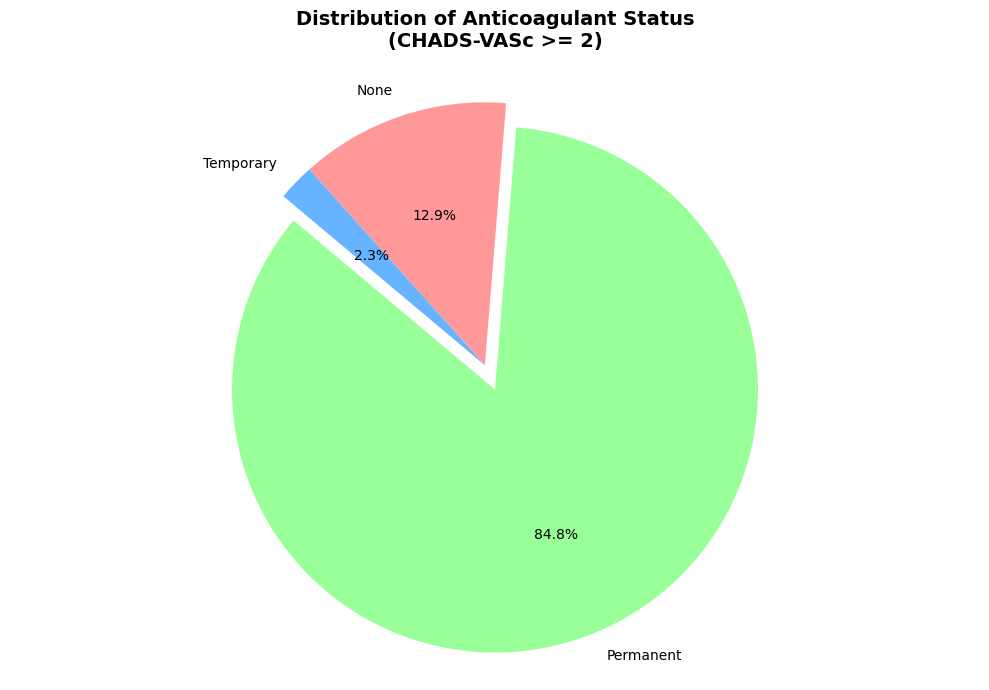

In [ ]:
import matplotlib.pyplot as plt

counts = df_with_score_greater_equal_than_2_regex["anticoagulant_status"].value_counts()

plt.figure(figsize=(10, 7))
colors = ["#99ff99", "#ff9999", "#66b3ff"]
explode = (0.1, 0, 0)

plt.pie(
    counts,
    labels=counts.index.str.capitalize(),
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
    explode=explode,
    shadow=False,
)  # Set to False for a flat look

plt.title(
    "Distribution of Anticoagulant Status\n(CHADS-VASc >= 2)",
    fontsize=14,
    fontweight="bold",
    pad=20,
)

plt.axis("equal")
plt.tight_layout()
plt.show()

We inspect the 123 entries that are false.

In [ ]:
df_to_inspect = df_with_score_greater_equal_than_2_regex[
    df_with_score_greater_equal_than_2_regex["anticoagulant_status"] == "none"
]
# print_context(df_to_inspect, chads_pattern)
print_section(df_to_inspect, "MEDICATIE")

Nothing remarkable to see which would lead us to think that the regex is faulty. 

In [ ]:
df_expert = pd.read_feather(r"Expert-based\results\intersection_model_train.feather")

df_with_score_greater_equal_than_2_expert = df_expert[
    (df_expert["reconstructed_score_intersection"].notna())
    & (df_expert["reconstructed_score_intersection"] >= 2)
]
df_with_score_greater_equal_than_2_expert["anticoagulant_status"] = (
    df_with_score_greater_equal_than_2_expert["sections"].apply(
        classify_anticoagulant_use
    )
)
print(df_with_score_greater_equal_than_2_expert["anticoagulant_status"].value_counts())

anticoagulant_status
permanent    3294
none          821
temporary      73
Name: count, dtype: int64


C:\Users\guest5\AppData\Local\Temp\ipykernel_9252\2848619024.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_with_score_greater_equal_than_2_expert['anticoagulant_status'] = df_with_score_greater_equal_than_2_expert['sections'].apply(classify_anticoagulant_use)


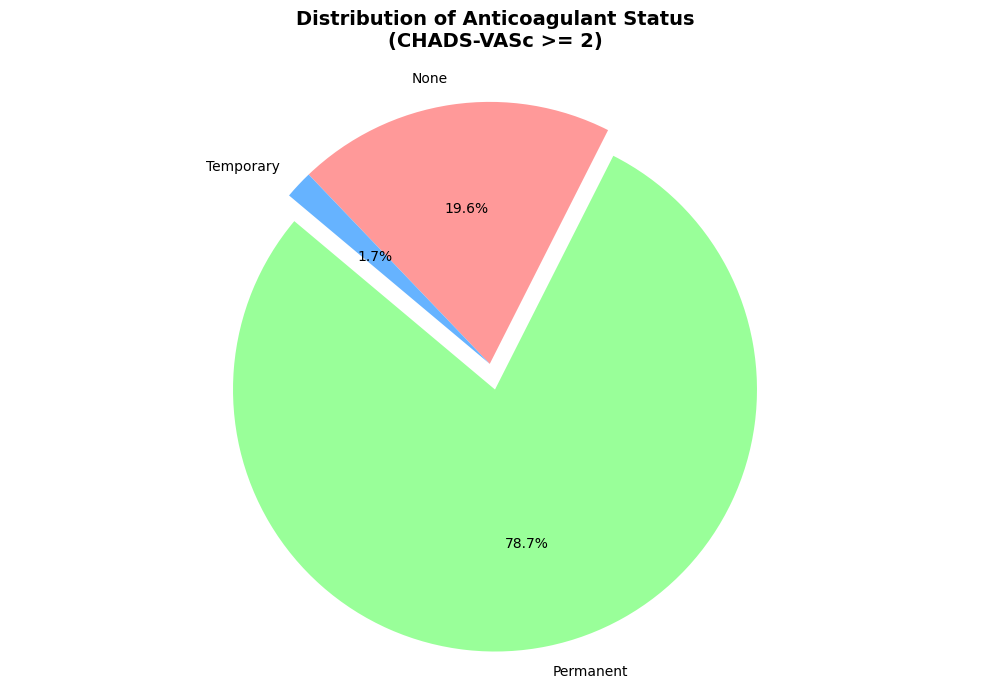

In [ ]:
import matplotlib.pyplot as plt

counts = df_with_score_greater_equal_than_2_expert[
    "anticoagulant_status"
].value_counts()

plt.figure(figsize=(10, 7))
colors = ["#99ff99", "#ff9999", "#66b3ff"]
explode = (0.1, 0, 0)

plt.pie(
    counts,
    labels=counts.index.str.capitalize(),
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
    explode=explode,
    shadow=False,
)  # Set to False for a flat look

plt.title(
    "Distribution of Anticoagulant Status\n(CHADS-VASc >= 2)",
    fontsize=14,
    fontweight="bold",
    pad=20,
)

plt.axis("equal")
plt.tight_layout()
plt.show()

In [ ]:
print(df_expert["reconstructed_score_intersection"].value_counts(dropna=False))

reconstructed_score_intersection
5    1032
4     975
3     734
6     571
2     499
1     315
7     273
0     115
8      80
9      24
Name: count, dtype: int64


### Check if the regex found entries are a subset of the component-based found entries
Case 1: greater than

In [ ]:
check_df = pd.merge(
    df_with_score_greater_equal_than_2_regex[
        df_with_score_greater_equal_than_2_regex["anticoagulant_status"].isin(
            ["permanent", "temporary"]
        )
    ][["unique_id", "anticoagulant_status"]],
    df_with_score_greater_equal_than_2_expert[["unique_id", "anticoagulant_status"]],
    on="unique_id",
    how="left",
    suffixes=("_regex", "_expert"),
)

check_df["anticoagulant_status_expert"] = check_df[
    "anticoagulant_status_expert"
].fillna("NOT_IN_EXPERT")

true_matches = (
    check_df["anticoagulant_status_regex"] == check_df["anticoagulant_status_expert"]
).sum()
total_regex_finds = len(check_df)
real_accuracy = (true_matches / total_regex_finds) * 100

print(f"Total Regex Findings: {total_regex_finds}")
print(
    f"Notes missing from Expert set: {len(check_df[check_df['anticoagulant_status_expert'] == 'NOT_IN_EXPERT'])}"
)
print(f"Adjusted Accuracy: {real_accuracy:.2f}%")

Total Regex Findings: 964
Notes missing from Expert set: 39
Adjusted Accuracy: 95.95%


In [28]:
df_mismatches = check_df[check_df["anticoagulant_status_expert"] == "NOT_IN_EXPERT"]
print(len(df_mismatches))

39


In [ ]:
df[df["unique_id"].isin(df_mismatches["unique_id"])][
    ["chadsvasc_score", "reconstructed_score_intersection", "text", "sections"]
]

In [ ]:
window = 100

for i, note in enumerate(
    df[df["unique_id"].isin(df_mismatches["unique_id"])]["text"].head(20)
):
    if not isinstance(note, str):
        continue
    match = re.search(chads_pattern, note, flags=re.IGNORECASE | re.VERBOSE)
    if match:
        start = max(match.start() - window, 0)
        end = min(match.end() + window, len(note))
        context = note[start:end]
        print(f"\nExample {i+1} (context around CHADS-VASc):\n...{context}...")
        print(f"Match: {match.group(0)}")
    else:
        print(f"\nExample {i+1} (no match found)\n")

# QI3: Proportie antico met negatieve Chadsvasc (<2)


In [ ]:
df_with_score_less_than_2_regex = df[
    (df["chadsvasc_score"].notna()) & (df["chadsvasc_score"] < 2)
]
print(len(df_with_score_less_than_2_regex))

df_with_score_less_than_2_regex["anticoagulant_status"] = (
    df_with_score_less_than_2_regex["sections"].apply(classify_anticoagulant_use)
)
print(df_with_score_less_than_2_regex["anticoagulant_status"].value_counts())

151
anticoagulant_status
permanent    68
none         58
temporary    25
Name: count, dtype: int64


C:\Users\guest5\AppData\Local\Temp\ipykernel_9252\2859384794.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_with_score_less_than_2_regex['anticoagulant_status'] = df_with_score_less_than_2_regex['sections'].apply(classify_anticoagulant_use)


In [ ]:
print("\nPercentage of notes with CHADS-VASc < 2 and on anticoagulants:")

# Calculate percentages
total = len(df_with_score_less_than_2_regex)
permanent_pct = (
    len(
        df_with_score_less_than_2_regex[
            df_with_score_less_than_2_regex["anticoagulant_status"] == "permanent"
        ]
    )
    / total
    * 100
)
temporary_pct = (
    len(
        df_with_score_less_than_2_regex[
            df_with_score_less_than_2_regex["anticoagulant_status"] == "temporary"
        ]
    )
    / total
    * 100
)

print(f"\n  Permanent/Chronic: {permanent_pct:.2f}%")
print(f"  Temporary/Durational: {temporary_pct:.2f}%")


Percentage of notes with CHADS-VASc < 2 and on anticoagulants:

  Permanent/Chronic: 45.03%
  Temporary/Durational: 16.56%


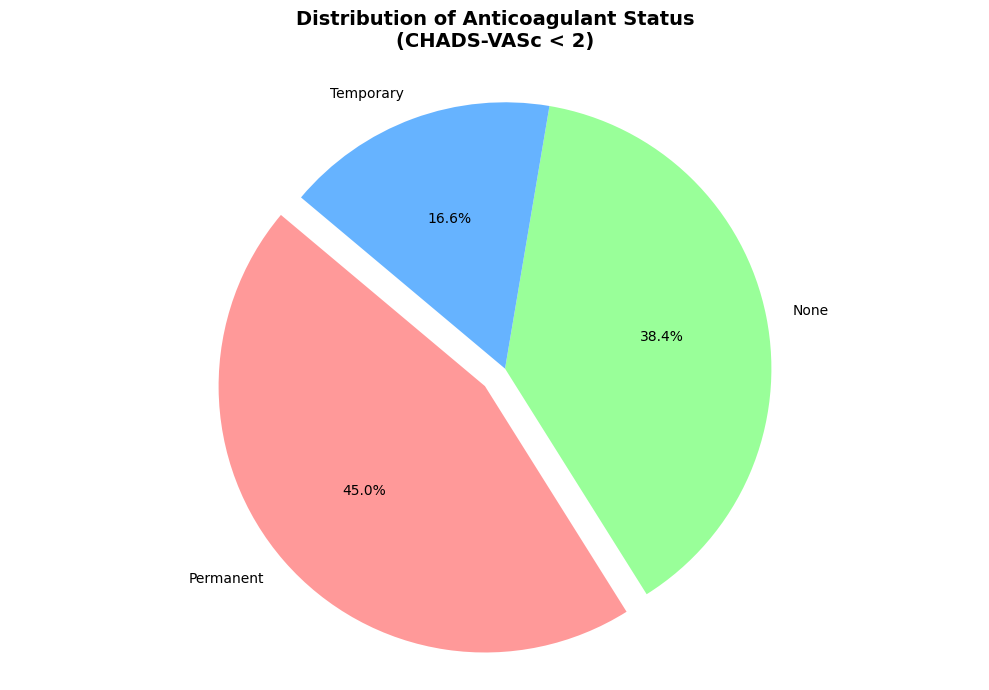

In [ ]:
import matplotlib.pyplot as plt

counts = df_with_score_less_than_2_regex["anticoagulant_status"].value_counts()

plt.figure(figsize=(10, 7))
colors = ["#ff9999", "#99ff99", "#66b3ff"]
explode = (0.1, 0, 0)

plt.pie(
    counts,
    labels=counts.index.str.capitalize(),
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
    explode=explode,
    shadow=False,
)  # Set to False for a flat look

plt.title(
    "Distribution of Anticoagulant Status\n(CHADS-VASc < 2)",
    fontsize=14,
    fontweight="bold",
    pad=20,
)

plt.axis("equal")
plt.tight_layout()
plt.show()

In [ ]:
df_with_score_less_than_2_expert = df_expert[
    (df_expert["reconstructed_score_intersection"].notna())
    & (df_expert["reconstructed_score_intersection"] < 2)
]
df_with_score_less_than_2_expert["anticoagulant_status"] = (
    df_with_score_less_than_2_expert["sections"].apply(classify_anticoagulant_use)
)

print(df_with_score_less_than_2_expert["anticoagulant_status"].value_counts())

anticoagulant_status
permanent    265
none         116
temporary     49
Name: count, dtype: int64


C:\Users\guest5\AppData\Local\Temp\ipykernel_9252\315945753.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_with_score_less_than_2_expert['anticoagulant_status'] = df_with_score_less_than_2_expert['sections'].apply(classify_anticoagulant_use)


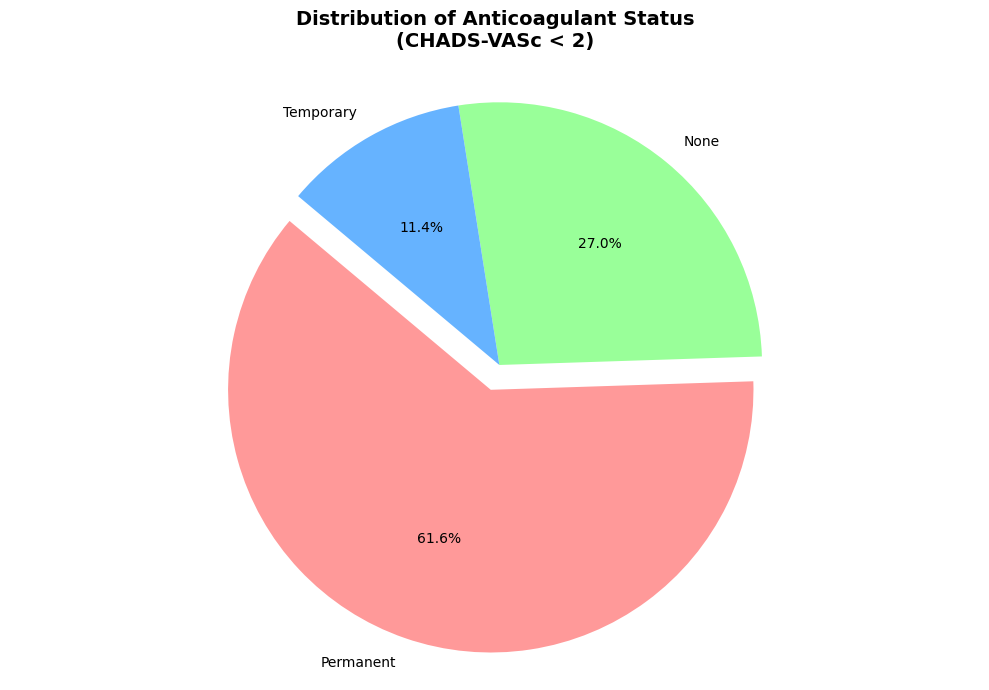

In [ ]:
import matplotlib.pyplot as plt

counts = df_with_score_less_than_2_expert["anticoagulant_status"].value_counts()

plt.figure(figsize=(10, 7))
colors = ["#ff9999", "#99ff99", "#66b3ff"]
explode = (0.1, 0, 0)

plt.pie(
    counts,
    labels=counts.index.str.capitalize(),
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
    explode=explode,
    shadow=False,
)  # Set to False for a flat look

plt.title(
    "Distribution of Anticoagulant Status\n(CHADS-VASc < 2)",
    fontsize=14,
    fontweight="bold",
    pad=20,
)

plt.axis("equal")
plt.tight_layout()
plt.show()

In [ ]:
check_df = pd.merge(
    df_with_score_less_than_2_regex[["unique_id", "anticoagulant_status"]],
    df_with_score_less_than_2_expert[["unique_id", "anticoagulant_status"]],
    on="unique_id",
    how="left",
    suffixes=("_regex", "_expert"),
)

check_df["anticoagulant_status_expert"] = check_df[
    "anticoagulant_status_expert"
].fillna("NOT_IN_EXPERT")

true_matches = (
    check_df["anticoagulant_status_regex"] == check_df["anticoagulant_status_expert"]
).sum()
total_regex_finds = len(check_df)
real_accuracy = (true_matches / total_regex_finds) * 100

print(f"Total Regex Findings: {total_regex_finds}")
print(
    f"Notes missing from Expert set: {len(check_df[check_df['anticoagulant_status_expert'] == 'NOT_IN_EXPERT'])}"
)
print(f"Adjusted Accuracy: {real_accuracy:.2f}%")

Total Regex Findings: 151
Notes missing from Expert set: 33
Adjusted Accuracy: 78.15%


In [ ]:
df[df["unique_id"].isin(df_mismatches["unique_id"])][
    ["chadsvasc_score", "reconstructed_score_intersection", "text", "sections"]
]